# Sprint 2 · Modelling
**Millennium BCP × FEP · Predicting daily account balances**

Sprint 1 ended with one clear message: most of the official error does not come from the daily ups and downs of a
balance but from choosing the wrong level for the accounts that live around zero. This notebook starts the modelling
work exactly there. Before fitting any model to the whole dataset, we ask a narrow question: for the near-zero
accounts, which way of choosing a level gives the best forecast under our three measures?

Two ideas compete. The first comes from the MAPE itself: because over-forecasting a small balance is punished much
more than under-forecasting it, the best constant is a weighted median in which small balances count more, and we
can lean the forecast towards zero when the sign is uncertain. The second is a two-step approach suggested in a
second opinion: first classify the sign of the balance and then predict its size with a robust loss. We test both
against the baselines of Sprint 1 with the same validation folds and the same decision rule.

The notebook only needs the CSV file provided by the professor, set in `DATA_PATH` below.

## 0. Setup

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4)

# ---- Parameters ---------------------------------------------------------------
DATA_PATH = "../data/raw/medium-dataset.csv"   # the only input of this notebook
HORIZON = 30                # forecast horizon (days)
NEAR_ZERO = 100.0           # |balance| below this (EUR) counts as near zero
EPS = 1.0                   # floor (EUR) for the weights 1/|balance| so that a cent does not dominate everything
RANDOM_STATE = 42
WINDOWS = [30, 60, 90, 180, 365]      # look-back windows (days) tried for the level
SHRINK = [1.0, 0.75, 0.5, 0.35, 0.25, 0.1, 0.0]   # shrinkage factors towards zero tried for the level
LAMBDAS = [0.0, 0.25, 0.5, 0.75]      # minimum weight kept by the sign-uncertainty shrinkage
rng = np.random.default_rng(RANDOM_STATE)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS_DIR = PROJECT_ROOT / "data" / "sprint2"
saved_files = []


def resolve_path(p):
    """Accept the path relative to the notebook folder or to the project root."""
    p = Path(p)
    for cand in (p, Path.cwd().parent / p, Path.cwd() / "data" / "raw" / p.name):
        if cand.exists():
            return cand
    raise FileNotFoundError(f"Data file not found: {p}")


def save_result(obj, name, description, index=True):
    """Write a Series/DataFrame to RESULTS_DIR/<name>.csv and register it in the index."""
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    df = obj.to_frame() if isinstance(obj, pd.Series) else obj
    df.to_csv(RESULTS_DIR / f"{name}.csv", index=index)
    saved_files.append({"file": f"{name}.csv", "description": description, "rows": df.shape[0], "columns": df.shape[1]})

## 1. The data, prepared as in Sprint 1

We first repeat the two corrections found in Sprint 1, so that this notebook runs from the raw file alone. Until
6 August 2022 each column holds the closing balance of the previous day, and the column of 5 August holds the sum of
two closing balances. We move the early columns back one day, repair the corrupted day and fill the one weekend gap
that the shift leaves.

In [2]:
raw = pd.read_csv(resolve_path(DATA_PATH)).set_index("ACCOUNT_ID")
raw.columns = pd.to_datetime(raw.columns)
raw = raw.astype("float64")

SWITCH_FIRST_NEW_LABEL = pd.Timestamp("2022-08-07")
CORRUPTED_LABEL = pd.Timestamp("2022-08-05")
NEXT_LABEL = pd.Timestamp("2022-08-06")


def realign_calendar(wide):
    """Return a frame where every column is the closing balance of that same date."""
    old = wide.loc[:, wide.columns < SWITCH_FIRST_NEW_LABEL].copy()
    new = wide.loc[:, wide.columns >= SWITCH_FIRST_NEW_LABEL]
    if CORRUPTED_LABEL in old.columns and NEXT_LABEL in old.columns:
        old[CORRUPTED_LABEL] = old[CORRUPTED_LABEL] - old[NEXT_LABEL]
    old.columns = old.columns - pd.Timedelta(days=1)
    out = pd.concat([old, new], axis=1)
    full = pd.date_range(out.columns.min(), out.columns.max(), freq="D")
    out = out.reindex(columns=full)
    for g in full.difference(pd.concat([old, new], axis=1).columns):
        out[g] = out[g + pd.Timedelta(days=1)]
    return out


bal = realign_calendar(raw)
print(f"{bal.shape[0]} accounts, {bal.shape[1]} days, {bal.columns.min().date()} to {bal.columns.max().date()}")

500 accounts, 1096 days, 2020-01-01 to 2022-12-31


## 2. How we keep score

We keep the rules of Sprint 1. The official MAPE leaves out only the exact zeros where it is undefined. Next to it we
report the median MAPE across accounts and the MAPE on balances of at least €100. A model is accepted only if it
improves the official MAPE without getting worse on the other two measures. The folds are the same: January 2022 and
the four last 30-day windows of 2022, each forecast with the data before it only.

In [3]:
def mape_official(actual, forecast):
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    ok = np.isfinite(a) & np.isfinite(f) & (a != 0)
    return 100 * np.mean(np.abs((a[ok] - f[ok]) / a[ok]))


def mape_per_account(actual, forecast):
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    ok = np.isfinite(a) & np.isfinite(f) & (a != 0)
    ape = np.where(ok, np.abs((a - f) / np.where(ok, a, 1)), np.nan)
    return 100 * np.nanmean(ape, axis=1)


METRICS = ["MAPE (official)", "median per-account MAPE", f"MAPE |actual|>={NEAR_ZERO:.0f}"]


def evaluate(actual, forecast):
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    f = np.broadcast_to(f, a.shape)
    ok = np.isfinite(a) & np.isfinite(f) & (np.abs(a) >= NEAR_ZERO)
    return {
        "MAPE (official)": mape_official(a, f),
        "median per-account MAPE": np.nanmedian(mape_per_account(a, f)),
        f"MAPE |actual|>={NEAR_ZERO:.0f}": 100 * np.mean(np.abs((a[ok] - f[ok]) / a[ok])),
    }


def passes_decision_rule(candidate, reference, tolerance=0.0):
    """Accepted if it improves the official MAPE and does not get worse (beyond `tolerance`, as a fraction)
    than the reference on the other two measures."""
    guards = ["median per-account MAPE", f"MAPE |actual|>={NEAR_ZERO:.0f}"]
    better = candidate["MAPE (official)"] < reference["MAPE (official)"]
    safe = all(candidate[m] <= reference[m] * (1 + tolerance) for m in guards)
    return bool(better and safe)


last_day = bal.columns.max()
origins = [pd.Timestamp("2021-12-31")] + [last_day - pd.Timedelta(days=HORIZON * k) for k in (4, 3, 2, 1)]
B = bal.to_numpy()
col_index = {d: i for i, d in enumerate(bal.columns)}
cut = {o: col_index[o] + 1 for o in origins}       # number of training days at each origin
print({str(o.date()): cut[o] for o in origins})

{'2021-12-31': 731, '2022-09-02': 976, '2022-10-02': 1006, '2022-11-01': 1036, '2022-12-01': 1066}


## 3. Which accounts are near zero?

We use the rules of section 15 of Sprint 1, recomputed at every fold from the last twelve months of its training
data, so that nothing from the test window leaks into the grouping. An account is dormant when its balance moves on
fewer than 5% of the days. Otherwise it is near-zero or in overdraft when more than a quarter of its days are within
€100 of zero or negative, stable positive when its variation is small relative to its level, and volatile positive
in the remaining cases.

In [4]:
def segments(T):
    """Rule-based segment of each account from the last 365 days of the training matrix T."""
    R = T[:, -365:]
    dR = np.diff(R, axis=1)
    valid = ~np.isnan(dR)
    activity = np.sum((dR != 0) & valid, 1) / np.maximum(valid.sum(1), 1)
    near = np.nanmean(np.where(np.isnan(R), np.nan, np.abs(R) < NEAR_ZERO), 1)
    neg = np.nanmean(np.where(np.isnan(R), np.nan, R < 0), 1)
    cv = np.nanstd(R, 1) / np.abs(np.nanmean(R, 1))
    return np.select([activity < 0.05, (near > 0.25) | (neg > 0.25), cv < 0.5],
                     ["dormant", "near-zero / overdraft", "stable positive"], default="volatile positive")


seg_by_fold = {o: segments(B[:, :cut[o]]) for o in origins}
display(pd.DataFrame({str((o + pd.Timedelta(days=1)).date()): pd.Series(s).value_counts()
                      for o, s in seg_by_fold.items()}).fillna(0).astype(int))

,2022-01-01,2022-09-03,2022-10-03,2022-11-02,2022-12-02
near-zero / overdraft,203,203,202,199,198
volatile positive,161,161,160,163,161
stable positive,136,136,138,138,141


The groups are stable from fold to fold, so conclusions about the near-zero segment will not depend on a lucky
split. From here on the near-zero accounts are the ones we study.

## 4. Candidate levels

Every candidate in this section is one level per account, held constant for the 30 days. That is deliberate. In
Sprint 1 we saw that a balance oscillates around a level, and that the oracle constant already reaches an official
MAPE of about 44%. Before adding any dynamics we want to know how close a constant chosen without peeking can get.

The first family are the weighted medians of the last N days, in which a balance counts in inverse proportion to its
size. For a given set of balances this is exactly the constant that minimises the MAPE, so it is the natural
estimator of the level. We try several values of N. The second family leans the level towards zero, either by a
fixed factor or by an amount that grows when the balance changed sign often in the window. The factor and the window
are not chosen by hand: for each fold they are tuned on the two 30-day windows just before the cut-off, using only
near-zero accounts, so that the test window stays untouched.

In [5]:
def weighted_median_inv(A, eps=EPS):
    """Per row: the constant c minimising sum |a - c| / max(|a|, eps) (weighted median), ignoring NaN and zeros."""
    valid = np.isfinite(A) & (A != 0)
    w = np.where(valid, 1.0 / np.maximum(np.abs(A), eps), 0.0)
    order = np.argsort(np.where(valid, A, np.inf), axis=1)
    As = np.take_along_axis(A, order, 1)
    cw = np.cumsum(np.take_along_axis(w, order, 1), 1)
    tot = cw[:, -1]
    idx = (cw >= tot[:, None] / 2).argmax(1)
    return np.where(tot > 0, As[np.arange(len(A)), idx], np.nan)


def sign_confidence(T, n):
    """|2p - 1| where p is the share of positive balances in the last n days: 1 when the sign never changes."""
    p = np.nanmean(np.where(np.isnan(T[:, -n:]), np.nan, T[:, -n:] > 0), 1)
    return np.abs(2 * p - 1)


def fill(x, fallback):
    return np.where(np.isfinite(x), x, fallback)


def level_candidates(T):
    """All constant-level candidates built from a training matrix T (accounts x days)."""
    last = T[:, -1]
    out = {"zero (forecast 0)": np.zeros_like(last),
           "naive (last value)": last,
           "median of last 30 days": fill(np.nanmedian(T[:, -30:], 1), last)}
    for n in WINDOWS:
        out[f"weighted median, N={n}"] = fill(weighted_median_inv(T[:, -n:]), last)
    return out


def tuned_level(T, mask, inner_origins=(60, 30)):
    """Pick (N, shrink) and (N, lambda) on the windows just before the end of T, using the accounts in `mask`."""
    best = {"shrink": (np.inf, None), "uncertainty": (np.inf, None)}
    for n in WINDOWS:
        for kind, grid in (("shrink", SHRINK), ("uncertainty", LAMBDAS)):
            for g in grid:
                score = 0.0
                for back in inner_origins:
                    Tin = T[:, :T.shape[1] - back]
                    A = T[:, T.shape[1] - back: T.shape[1] - back + HORIZON]
                    lvl = fill(weighted_median_inv(Tin[:, -n:]), Tin[:, -1])
                    lvl = lvl * g if kind == "shrink" else lvl * (g + (1 - g) * sign_confidence(Tin, n))
                    score += mape_official(A[mask], np.broadcast_to(lvl[mask, None], A[mask].shape))
                if score < best[kind][0]:
                    best[kind] = (score, (n, g))
    return {k: v[1] for k, v in best.items()}


def apply_tuned(T, params):
    last = T[:, -1]
    n, s = params["shrink"]
    n2, lam = params["uncertainty"]
    return {
        "weighted median, tuned shrinkage": fill(weighted_median_inv(T[:, -n:]), last) * s,
        "weighted median, tuned sign-uncertainty shrinkage":
            fill(weighted_median_inv(T[:, -n2:]), last) * (lam + (1 - lam) * sign_confidence(T, n2)),
    }

## 5. The two-step alternative

The second opinion suggests splitting the problem. A classifier decides whether the balance of the next month will be
positive or negative, and a second step predicts its size with a robust loss such as the mean absolute error. We
implement it in a simple, fair way. The classifier is a gradient-boosted tree trained on the near-zero accounts, with
features that describe the recent sign pattern of an account (share of positive days in the last 30, 90 and 180 days,
the sign of the last balance and the last balance relative to the typical size). Its examples come from many past
cut-offs inside the training data, and its target is the sign of the median balance over the following 30 days. The
size is the median absolute balance of the last 90 days, which is the constant that minimises the absolute error of
the size.

We also try the same classifier with a size chosen to minimise the MAPE, the weighted median of the absolute
balances. Comparing the two tells us whether any difference comes from the sign step or from the loss used for the
size.

In [6]:
def sign_features(T, j):
    """Features at cut-off j (using columns < j of T)."""
    X = {}
    for n in (30, 90, 180):
        W = T[:, j - n:j]
        X[f"pos_{n}"] = np.nanmean(np.where(np.isnan(W), np.nan, W > 0), 1)
    typical = np.nanmedian(np.abs(T[:, j - 90:j]), 1)
    last = T[:, j - 1]
    X["last_positive"] = (last > 0).astype(float)
    X["last_over_typical"] = last / np.maximum(typical, EPS)
    return pd.DataFrame(X)


def hurdle_level(T, mask, step=10):
    """Sign classifier trained on past cut-offs of the accounts in `mask`; returns a signed level for all accounts."""
    t = T.shape[1]
    X, y = [], []
    for j in range(180, t - HORIZON + 1, step):
        f = sign_features(T, j)
        fut = np.nanmedian(T[:, j:j + HORIZON], 1)
        keep = mask & np.isfinite(fut) & (fut != 0)
        X.append(f[keep]); y.append((fut[keep] > 0).astype(int))
    X = pd.concat(X); y = np.concatenate(y)
    clf = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=15, min_child_samples=20,
                             random_state=RANDOM_STATE, verbose=-1)
    clf.fit(X, y)
    p = clf.predict_proba(sign_features(T, t))[:, 1]
    sign = np.where(p >= 0.5, 1.0, -1.0)
    recent = np.abs(T[:, -90:])
    last = T[:, -1]
    return {
        "two-step: sign classifier + median size (MAE)": sign * fill(np.nanmedian(recent, 1), np.abs(last)),
        "two-step: sign classifier + weighted-median size (MAPE)": sign * fill(weighted_median_inv(recent), np.abs(last)),
    }

## 6. The experiment

For each fold we cut the data, build every candidate from the training part only, and score it on the next 30 days.
The near-zero segment is the focus. We also score the plain candidates on the stable positive accounts, to check that
leaning towards zero does not harm the accounts where the level was already easy.

In [7]:
rows = []
tuned_log = []
for o in origins:
    T = B[:, :cut[o]]
    A = B[:, cut[o]:cut[o] + HORIZON]
    seg = seg_by_fold[o]
    near_mask = seg == "near-zero / overdraft"
    params = tuned_level(T, near_mask)
    tuned_log.append({"fold": str((o + pd.Timedelta(days=1)).date()), "shrinkage (N, factor)": params["shrink"],
                      "sign-uncertainty (N, lambda)": params["uncertainty"]})
    cands = {**level_candidates(T), **apply_tuned(T, params), **hurdle_level(T, near_mask)}
    complex_names = {"weighted median, tuned shrinkage", "weighted median, tuned sign-uncertainty shrinkage",
                     "two-step: sign classifier + median size (MAE)",
                     "two-step: sign classifier + weighted-median size (MAPE)"}
    for name, lvl in cands.items():
        for sname in ("near-zero / overdraft", "stable positive"):
            m = seg == sname
            if name in complex_names and sname != "near-zero / overdraft":
                continue
            if m.sum() == 0:
                continue
            rows.append({"fold": str((o + pd.Timedelta(days=1)).date()), "segment": sname, "method": name,
                         "accounts": int(m.sum()), **evaluate(A[m], np.broadcast_to(lvl[m, None], A[m].shape))})
res = pd.DataFrame(rows)
tuned_log = pd.DataFrame(tuned_log)
display(tuned_log)
save_result(res, "02_level_experiment_by_fold", "Constant-level candidates by fold and segment, all metrics", index=False)
save_result(tuned_log, "02_tuned_parameters", "Parameters chosen on the inner windows for each fold", index=False)

,fold,"shrinkage (N, factor)","sign-uncertainty (N, lambda)"
0,2022-01-01,"(180, 0.1)","(365, 0.0)"
1,2022-09-03,"(30, 0.0)","(90, 0.0)"
2,2022-10-03,"(30, 0.0)","(365, 0.0)"
3,2022-11-02,"(30, 0.0)","(365, 0.0)"
4,2022-12-02,"(90, 0.1)","(180, 0.0)"


In [8]:
summary = {s: res[res.segment == s].groupby("method")[METRICS].mean().sort_values("MAPE (official)")
           for s in ("near-zero / overdraft", "stable positive")}
for s, tab in summary.items():
    print(f"\n=== {s} ===")
    display(tab.round(1))
    save_result(tab, f"02_level_experiment_summary_{s.split()[0].replace('-', '_')}",
                f"Mean over folds of each metric for the {s} segment")


=== near-zero / overdraft ===


,MAPE (official),median per-account MAPE,MAPE |actual|>=100
method,,,
zero (forecast 0),100.0,100.0,100.0
"weighted median, tuned shrinkage",100.7,99.9,99.6
"weighted median, tuned sign-uncertainty shrinkage",111.6,99.9,96.1
"weighted median, N=180",119.4,99.7,94.3
"weighted median, N=90",122.9,99.3,92.6
"weighted median, N=365",123.5,99.8,96.6
two-step: sign classifier + weighted-median size (MAPE),159.5,98.3,90.3
"weighted median, N=60",173.7,99.0,90.7
"weighted median, N=30",204.9,98.8,90.5



=== stable positive ===


,MAPE (official),median per-account MAPE,MAPE |actual|>=100
method,,,
zero (forecast 0),100.0,100.0,100.0
"weighted median, N=365",1865.5,25.2,42.4
"weighted median, N=180",1941.5,17.6,35.4
"weighted median, N=90",1975.2,14.8,30.4
"weighted median, N=60",1981.9,13.0,28.1
naive (last value),2025.5,9.2,27.9
"weighted median, N=30",2029.7,11.0,28.4
median of last 30 days,9352.7,10.8,29.2


## 7. Reading the results

We apply the decision rule against three references: the last balance, the median of the last 30 days and, new in
this notebook, a forecast of exactly zero. A zero forecast has a MAPE of exactly 100% for every account and every
non-zero balance, whatever the balance is. It is not a model, but it is a ruthless benchmark, because the percentage
error of any forecast that leans too high is unbounded while the one of a zero forecast is capped.

,accepted vs naive (last value),accepted vs median of last 30 days,accepted vs zero (forecast 0)
zero (forecast 0),True,True,NaN
"weighted median, tuned shrinkage",True,True,False
"weighted median, tuned sign-uncertainty shrinkage",True,True,False
"weighted median, N=180",True,True,False
"weighted median, N=90",True,True,False
"weighted median, N=365",True,True,False
two-step: sign classifier + weighted-median size (MAPE),True,True,False
"weighted median, N=60",True,True,False
"weighted median, N=30",True,True,False
two-step: sign classifier + median size (MAE),True,False,False


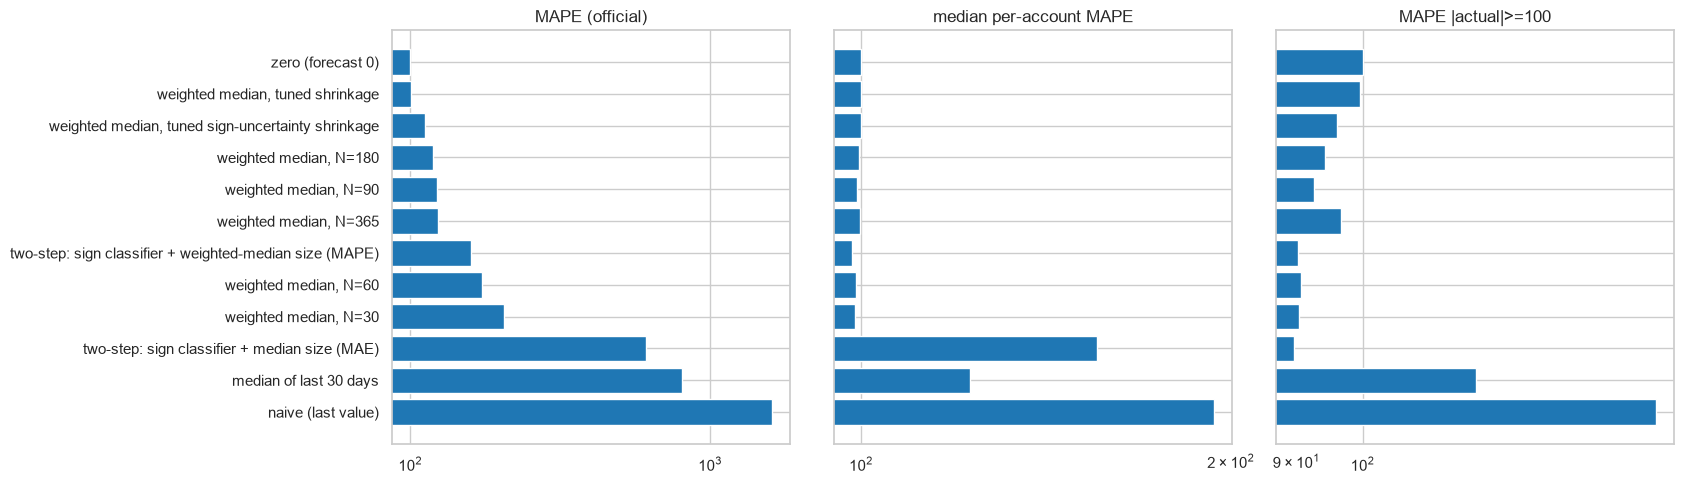

In [9]:
near = summary["near-zero / overdraft"]
verdict = pd.DataFrame({
    f"accepted vs {ref}": {m: passes_decision_rule(near.loc[m], near.loc[ref]) for m in near.index if m != ref}
    for ref in ("naive (last value)", "median of last 30 days", "zero (forecast 0)")})
display(verdict)
save_result(verdict, "02_decision_rule_near_zero", "Decision-rule verdict of every near-zero candidate against the two baselines")

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
order = near.sort_values("MAPE (official)").index
for ax, m in zip(axes, METRICS):
    ax.barh(order, near.loc[order, m], color="tab:blue"); ax.set_title(m); ax.set_xscale("log")
axes[0].invert_yaxis(); plt.tight_layout(); plt.show()

The first result is the size of the gain. In the near-zero segment the last balance has an official MAPE of about
1 600% and the median of the last 30 days about 800%, while the weighted medians of the last 90 to 365 days are
around 120%. That confirms the main lesson of Sprint 1: the level matters more than anything else for these
accounts, and choosing it with the MAPE in mind removes more than 90% of the official error.

The second result is a warning. The zero forecast scores exactly 100% on the three measures, and the tuned
shrinkage ends up choosing factors between 0 and 0.1, which is a forecast of almost zero (100.7% official). The
search was free to keep the level and it chose to give it up. For accounts that cross zero all the time, no constant
level is reliably within a factor of two of the true balance, so the best constant is the one that costs exactly
100%. The weighted medians do a little better than zero only on the balances of at least €100 (90 to 96% against
100%) and they do it by being right about sign and size on the days when the balance is not tiny, at the price of
a higher official score.

The third result concerns the two-step idea. With the size predicted by a mean absolute error the official MAPE is
about 610%, because that loss ignores how costly it is to over-forecast a small balance. With a size chosen for the
MAPE it falls to about 160%, but that is still worse than the plain weighted median of the last 90 days (about 123%),
so the sign classifier did not add information beyond what the share of positive days already says. This does not
mean that sign prediction is useless in general. It means that a classifier built only on the recent sign pattern
of the account has nothing to learn from, and that any future version needs features that carry new information,
such as the calendar (the 8th, the end of the month) and the amounts of recurring payments.

The fourth result is about the other segment. On stable positive accounts the weighted median is worse than the
last balance or the median of 30 days on the typical account (13 to 25% against 9 to 11%), so leaning towards zero
should be reserved for the accounts that need it, which supports the segmented strategy decided in Sprint 1. The
official MAPE of that segment is large for every candidate except zero, because a few accounts classified as stable
in the past fall close to zero in the test window.

What we take forward is a floor and a question. The floor is that every model for near-zero accounts must beat a
100% MAPE, so the zero forecast becomes a reference of our decision rule. The question is how to do better than the
floor, which a constant level cannot. That needs the within-month movement: the day of the month, the end-of-month
salary and the 8th, so that the forecast moves with the calendar instead of staying flat. Section 8 tests exactly
that, and section 9 returns to the stable accounts whose official score looked so odd.

## 8. Can the calendar beat the zero floor?

A constant level cannot go below 100% for accounts that cross zero all the time. But balances do not move at random:
salaries, pensions and debits come on fixed days of the month, so an account may be reliably positive on some days of
the month and reliably negative on others. We build a calendar profile for each account: for every day we want to
forecast, we take the balances the account had on the same day of the month (give or take two days) during the last
year, and keep their weighted median. This is the same MAPE-optimal estimator as before, now applied to days that
share a position in the month.

A profile alone still carries the risk of being wrong about the sign, which is what costs so much in percentage terms.
So we add a gate: we only use the profile on days when at least a share q of the past balances for that day of the
month have the same sign as the profile, and we forecast zero otherwise. The idea is to take a risk only when the
account has been consistent. The share q, and whether to halve the profile, are chosen on the two 30-day windows
before each cut-off, like in section 4.

In [10]:
dom = bal.columns.day.to_numpy()          # day of the month of every column of the matrix


def profile_parts(end, M=365, tol=2):
    """For the HORIZON days after column `end`: calendar-profile level and the share of past same-day balances that have
    the same sign as it. Uses columns before `end` only."""
    hist = np.arange(max(0, end - M), end)
    hd = dom[hist]
    T = B[:, :end]
    P = np.full((B.shape[0], HORIZON), np.nan)
    C = np.full_like(P, np.nan)
    for h in range(HORIZON):
        diff = np.abs(hd - dom[end + h])
        diff = np.minimum(diff, 31 - diff)                 # day 31 and day 1 are neighbours
        X = T[:, hist[diff <= tol]]
        med = weighted_median_inv(X)
        P[:, h] = med
        C[:, h] = np.nanmean(np.where(np.isnan(X), np.nan, np.sign(X) == np.sign(med)[:, None]), 1)
    return np.where(np.isfinite(P), P, T[:, -1:]), C


def gated(P, C, q, s):
    """Profile (times s) on days with sign agreement >= q, zero otherwise."""
    return np.where(C >= q, P * s, 0.0)


Q_GRID, S_GRID = [0.6, 0.7, 0.8, 0.9, 1.0], [1.0, 0.5]
Q_FIXED = 0.9
cal_rows, cal_params = [], []
for o in origins:
    e = cut[o]
    A = B[:, e:e + HORIZON]
    m = seg_by_fold[o] == "near-zero / overdraft"
    # tune q and s on the two inner windows
    inner = [(e - 60, profile_parts(e - 60)), (e - 30, profile_parts(e - 30))]
    scores = {}
    for q in Q_GRID:
        for sh in S_GRID:
            scores[(q, sh)] = sum(mape_official(B[m, ie:ie + HORIZON], gated(P, C, q, sh)[m]) for ie, (P, C) in inner)
    q_best, s_best = min(scores, key=scores.get)
    cal_params.append({"fold": str((o + pd.Timedelta(days=1)).date()), "q": q_best, "profile factor": s_best})
    P, C = profile_parts(e)
    cands = {"zero (forecast 0)": np.zeros_like(A),
             "weighted median, N=180 (constant)": np.repeat(fill(weighted_median_inv(B[:, e - 180:e]), B[:, e - 1])[:, None], HORIZON, 1),
             "calendar profile": P,
             "calendar profile, halved": 0.5 * P,
             f"gated calendar profile, q={Q_FIXED} (fixed)": gated(P, C, Q_FIXED, 1.0),
             "gated calendar profile, tuned": gated(P, C, q_best, s_best)}
    for name, f in cands.items():
        cal_rows.append({"fold": str((o + pd.Timedelta(days=1)).date()), "method": name, **evaluate(A[m], f[m])})
cal = pd.DataFrame(cal_rows)
cal_params = pd.DataFrame(cal_params)
cal_summary = cal.groupby("method")[METRICS].mean().sort_values("MAPE (official)")
display(cal_params)
display(cal_summary.round(1))
save_result(cal, "02_calendar_profile_by_fold", "Near-zero accounts: calendar-profile forecasts by fold", index=False)
save_result(cal_summary, "02_calendar_profile_summary", "Near-zero accounts: calendar-profile forecasts, mean over folds")
save_result(cal_params, "02_calendar_profile_tuned_parameters", "Gate threshold and profile factor chosen on the inner windows", index=False)

,fold,q,profile factor
0,2022-01-01,1.0,0.5
1,2022-09-03,1.0,0.5
2,2022-10-03,1.0,0.5
3,2022-11-02,1.0,1.0
4,2022-12-02,1.0,1.0


,MAPE (official),median per-account MAPE,MAPE |actual|>=100
method,,,
"gated calendar profile, tuned",95.9,100.0,94.2
"gated calendar profile, q=0.9 (fixed)",96.7,99.2,88.6
zero (forecast 0),100.0,100.0,100.0
"calendar profile, halved",110.7,97.6,92.4
"weighted median, N=180 (constant)",119.4,99.7,94.3
calendar profile,128.7,97.2,87.4


In [11]:
zero_ref = cal_summary.loc["zero (forecast 0)"]
cal_verdict = pd.Series({m: passes_decision_rule(cal_summary.loc[m], zero_ref) for m in cal_summary.index if m != zero_ref.name},
                        name="accepted against the zero forecast")
display(cal_verdict.to_frame())
pivot = cal.pivot(index="fold", columns="method", values="MAPE (official)")
wins = pivot.drop(columns="zero (forecast 0)").lt(pivot["zero (forecast 0)"], axis=0)
display(wins.sum().rename("folds (of 5) with a lower official MAPE than zero").to_frame())
display(pivot.round(1))
save_result(cal_verdict.to_frame(), "02_calendar_profile_decision_rule", "Decision-rule verdict against the zero forecast")

# share of near-zero account-days on which the gate lets the profile through
cover = {}
for o, (q_t, s_t) in zip(origins, zip(cal_params["q"], cal_params["profile factor"])):
    m = seg_by_fold[o] == "near-zero / overdraft"
    _, C = profile_parts(cut[o])
    cover[str((o + pd.Timedelta(days=1)).date())] = {"q=0.9 (fixed)": 100 * np.mean(C[m] >= Q_FIXED),
                                                     "tuned": 100 * np.mean(C[m] >= q_t)}
coverage = pd.DataFrame(cover).T
display(coverage.round(1).rename(columns=lambda c: f"% of days with a non-zero forecast, {c}"))
save_result(coverage, "02_calendar_profile_coverage", "Share (%) of near-zero account-days where the gated profile is used instead of zero")

,accepted against the zero forecast
"gated calendar profile, tuned",True
"gated calendar profile, q=0.9 (fixed)",True
"calendar profile, halved",False
"weighted median, N=180 (constant)",False
calendar profile,False


,folds (of 5) with a lower official MAPE than zero
method,
calendar profile,0
"calendar profile, halved",0
"gated calendar profile, q=0.9 (fixed)",3
"gated calendar profile, tuned",5
"weighted median, N=180 (constant)",0


method,calendar profile,"calendar profile, halved","gated calendar profile, q=0.9 (fixed)","gated calendar profile, tuned","weighted median, N=180 (constant)",zero (forecast 0)
fold,,,,,,
2022-01-01,131.9,110.0,93.9,96.5,142.2,100.0
2022-09-03,137.7,115.1,101.3,97.6,124.8,100.0
2022-10-03,122.8,108.3,95.3,96.3,115.3,100.0
2022-11-02,144.7,119.5,92.7,93.1,106.2,100.0
2022-12-02,106.3,100.4,100.1,96.2,108.3,100.0


,"% of days with a non-zero forecast, q=0.9 (fixed)","% of days with a non-zero forecast, tuned"
2022-01-01,26.0,11.4
2022-09-03,27.7,13.4
2022-10-03,27.7,13.4
2022-11-02,29.3,15.3
2022-12-02,30.3,15.8


The calendar helps, but only when we are careful with it. The profile on its own is worse than zero on the official
score (129%), and even halved it stays above 100%, because on the days when the account is not where its history says
it should be, the percentage error is large. The gate changes that. Letting the profile through only when the past
balances of that day of the month agree on the sign brings the official MAPE to 96% to 97%, below the zero floor, and
lowers the MAPE on balances of at least €100 to 89% to 94%. The version tuned on the inner windows chose the strictest
gate (q = 1) in every fold and beat zero on the official score in all five folds. The fixed gate of 0.9 does so in
three folds, and its better score on the larger balances comes at the cost of being sometimes worse than zero.

We should be honest about how small this gain is and where it comes from. The gate lets the profile through on only
11% to 16% of the near-zero account-days (26% to 30% for q = 0.9), and on the rest the forecast is still zero. A
gain of four points on a base of 100 is real in the sense that it is consistent across folds and passes our decision
rule against the zero forecast, but it is modest, and the median MAPE of the typical account does not improve beyond
the floor (100% for the tuned version). In practice the calendar tells us on which days it is safe to forecast a
value and on which days we should not. It does not make these accounts predictable.

## 9. Stable accounts that end near zero

In section 6 the stable positive accounts had an official MAPE of around 2 000% for every candidate, while the typical
account was at 9 to 25%. Something must dominate the pooled score. We look at which accounts, and at whether they
could have been seen coming. For every fold we list the stable accounts whose balance gets within €100 of zero
during the test window, and the share of the segment's total percentage error that each account produces with the
last-balance forecast.

In [12]:
stable_rows = []
for o in origins:
    e = cut[o]
    T = B[:, :e]; A = B[:, e:e + HORIZON]
    m = seg_by_fold[o] == "stable positive"
    last = T[:, -1]
    R = T[:, -365:]
    ape = np.abs(A - last[:, None]) / np.where(A == 0, np.nan, np.abs(A))
    for i in np.where(m)[0]:
        stable_rows.append({"fold": str((o + pd.Timedelta(days=1)).date()), "account": bal.index[i], "last balance": last[i],
                            "median last year": np.nanmedian(R[i]), "min last year": np.nanmin(R[i]),
                            "min / median": np.nanmin(R[i]) / np.nanmedian(R[i]),
                            "min |actual|": np.nanmin(np.abs(A[i])), "error total": np.nansum(ape[i]),
                            "ends near zero": np.nanmin(np.abs(A[i])) < NEAR_ZERO})
st = pd.DataFrame(stable_rows)
st["share of segment error"] = st["error total"] / st.groupby("fold")["error total"].transform("sum")
display(st.sort_values("share of segment error", ascending=False).head(8).round(2))
save_result(st, "02_stable_accounts_ending_near_zero", "Stable positive accounts: warning features and error contribution per fold", index=False)

,fold,account,last balance,median last year,min last year,min / median,min |actual|,error total,ends near zero,share of segment error
501,2022-11-02,328,133909.54,123438.43,109063.67,0.88,2.29,409340.70,True,1.00
276,2022-10-03,13,6022.65,5451.00,31.50,0.01,24.88,2693.39,True,0.73
149,2022-09-03,45,37911.90,36521.86,13966.38,0.38,808.27,648.25,False,0.41
48,2022-01-01,204,2200.16,12843.21,41.06,0.00,17.30,1109.20,True,0.40
68,2022-01-01,261,1671.09,6043.27,315.61,0.05,7.99,585.47,True,0.21
581,2022-12-02,137,11004.73,7824.49,1252.10,0.16,93.58,166.40,True,0.15
675,2022-12-02,445,173224.50,86375.80,69170.56,0.80,31042.32,89.62,False,0.08
219,2022-09-03,308,535.40,1421.74,310.76,0.22,11.62,110.47,True,0.07


One account in one fold produces practically all of the segment's error. Its balance, above €100 000, falls to a
few euros inside the window, and nothing in its history warns about it: its lowest balance of the last year was 88%
of its median. This is an event that no forecasting method could have predicted, and on its own it moves the pooled
score of that fold by about 100 percentage points. We cannot fix it, but we should keep it in mind when we compare
official scores, because a single account can decide a fold.

The other accounts that end near zero look different: their lowest balance of the last year had already been a small
fraction of their usual level. This suggests a warning rule for the stable accounts, which we test next: flag those
whose lowest balance of the last year was below 20% of their median.

In [13]:
flag_rows = []
for o in origins:
    e = cut[o]
    T = B[:, :e]; A = B[:, e:e + HORIZON]
    seg = seg_by_fold[o]
    R = T[:, -365:]
    ratio = np.nanmin(R, 1) / np.nanmedian(R, 1)
    base = seg == "stable positive"
    ends_near = np.nanmin(np.abs(A), 1) < NEAR_ZERO
    for name, mm in (("stable, all", base), ("stable, not flagged", base & (ratio >= 0.2)),
                     ("stable, flagged (min < 20% of median)", base & (ratio < 0.2))):
        flag_rows.append({"fold": str((o + pd.Timedelta(days=1)).date()), "group": name, "accounts": int(mm.sum()),
                          "ending near zero": int((mm & ends_near).sum()), **evaluate(A[mm], T[mm, -1:])})
flags = pd.DataFrame(flag_rows)
flag_summary = flags.groupby("group")[["accounts", "ending near zero"] + METRICS].mean()
display(flag_summary.round(1))
save_result(flag_summary, "02_stable_warning_flag", "Stable positive accounts split by a warning flag (lowest balance below 20% of the median), last-value forecast")

,accounts,ending near zero,MAPE (official),median per-account MAPE,MAPE |actual|>=100
group,,,,,
"stable, all",137.8,2.6,2025.5,9.2,27.9
"stable, flagged (min < 20% of median)",25.0,2.2,154.5,26.2,54.0
"stable, not flagged",112.8,0.4,2437.5,7.7,21.9


The rule separates two very different groups. The 25 stable accounts per fold that are flagged have a typical error of
26% with the last balance, against 8% for the others, and they are the ones that end near zero more often (2.2 of the
2.6 accounts per fold that do so). So these accounts were not really stable, and the segment rule of Sprint 1, which
looks only at the average variation, lets them in. Among the accounts that are not flagged, the typical error falls from
9.2% to 7.7%. The official MAPE of the unflagged group is still very high, but that is the single €134 000 account
discussed above, which the flag cannot see.

We take two decisions forward. The segment rule gets an extra condition, so that a stable account must also have kept
its balance above 20% of its median during the last year, and the flagged accounts go to the near-zero strategy of
section 8. And we will report the official MAPE of the stable group together with its version without the largest
contributor, so that one unpredictable event does not decide a comparison between models.

## 10. Index of saved results

In [14]:
index = pd.DataFrame(saved_files)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
index.to_csv(RESULTS_DIR / "00_index.csv", index=False)
index

,file,description,rows,columns
0,02_level_experiment_by_fold.csv,"Constant-level candidates by fold and segment,...",100,7
1,02_tuned_parameters.csv,Parameters chosen on the inner windows for eac...,5,3
2,02_level_experiment_summary_near_zero.csv,Mean over folds of each metric for the near-ze...,12,3
3,02_level_experiment_summary_stable.csv,Mean over folds of each metric for the stable ...,8,3
4,02_decision_rule_near_zero.csv,Decision-rule verdict of every near-zero candi...,12,3
5,02_calendar_profile_by_fold.csv,Near-zero accounts: calendar-profile forecasts...,30,5
6,02_calendar_profile_summary.csv,Near-zero accounts: calendar-profile forecasts...,6,3
7,02_calendar_profile_tuned_parameters.csv,Gate threshold and profile factor chosen on th...,5,3
8,02_calendar_profile_decision_rule.csv,Decision-rule verdict against the zero forecast,5,1
9,02_calendar_profile_coverage.csv,Share (%) of near-zero account-days where the ...,5,2
